# 04 多因子模型

## 目标
- 因子标准化：去极值、中性化、Z-score
- 因子合成：等权 / IC加权 / IC_IR加权
- 构建复合因子
- 月度选股策略：按复合因子排名选Top-K

## 方法
经典的截面多因子模型：在每个调仓日，将多个因子合成为一个综合得分，
按得分排名选股。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('✓ 依赖加载完毕')

✓ 依赖加载完毕


## 2. 加载数据

In [2]:
close_df = pd.read_csv('data/close_df.csv', index_col=0, parse_dates=True)
ret_df = pd.read_csv('data/ret_df.csv', index_col=0, parse_dates=True)
# dtype={1: str} 确保 ticker 不被读成整数
factor_wide = pd.read_csv('data/factor_wide.csv', index_col=[0, 1], dtype={1: str})
factor_wide.index = pd.MultiIndex.from_arrays([
    pd.to_datetime(factor_wide.index.get_level_values(0)),
    factor_wide.index.get_level_values(1)
], names=['date', 'ticker'])
factor_meta = pd.read_csv('data/factor_meta.csv')

# 加载筛选后的因子
try:
    selected_factors = pd.read_csv('data/selected_factors.csv')['factor'].tolist()
    print(f'加载筛选因子: {len(selected_factors)} 个')
except FileNotFoundError:
    selected_factors = factor_wide.columns.tolist()
    print(f'使用全部 {len(selected_factors)} 个因子')

selected_factors = [f for f in selected_factors if f in factor_wide.columns]
factors = factor_wide[selected_factors].copy()

dmin = factors.index.get_level_values('date').min().strftime('%Y-%m-%d')
dmax = factors.index.get_level_values('date').max().strftime('%Y-%m-%d')
print(f'因子矩阵: {factors.shape}')
print(f'日期范围: {dmin} ~ {dmax}')
print(f'因子列表: {selected_factors}')

加载筛选因子: 9 个
因子矩阵: (28680, 9)
日期范围: 2023-01-03 ~ 2025-12-31
因子列表: ['ma_dev_5d', 'williams_r', 'drawdown_20d', 'mom_20d', 'mfi_14', 'macd', 'vol_ratio_5d', 'obv_chg_5d', 'mom_60d']


## 3. 因子预处理

### 3.1 缺失值填充 & 去极值 & Z-Score标准化

In [3]:
def winsorize_series(s, limits=0.025):
    """MAD法去极值：用中位数±N倍MAD截断"""
    median = s.median()
    mad = (s - median).abs().median()
    if mad == 0:
        return s
    upper = median + 5 * mad
    lower = median - 5 * mad
    return s.clip(lower=lower, upper=upper)


def process_factors_cross_section(factors_df, ret_cross):
    """
    对单个截面进行因子处理：
    1. 缺失值用截面中位数填充
    2. MAD去极值
    3. Z-Score标准化
    """
    processed = factors_df.copy()
    
    for col in processed.columns:
        s = processed[col].astype(float)
        
        # 填充缺失
        s = s.fillna(s.median())
        
        # 去极值
        s = winsorize_series(s)
        
        # Z-score
        std = s.std()
        if std == 0:
            processed[col] = 0
        else:
            processed[col] = (s - s.mean()) / std
    
    return processed

In [4]:
%%time

# 对每个交易日截面做标准化
dates = factors.index.get_level_values('date').unique()
standardized_list = []

for date in dates:
    try:
        f_cross = factors.loc[date].copy()
        r_cross = ret_df.loc[date] if date in ret_df.index else None
        std_cross = process_factors_cross_section(f_cross, r_cross)
        std_cross['date'] = date
        standardized_list.append(std_cross)
    except:
        continue

factors_std = pd.concat(standardized_list)
factors_std.index.name = 'ticker'
factors_std = factors_std.reset_index().set_index(['date', 'ticker'])

print(f'✓ 因子标准化完成: {factors_std.shape}')

✓ 因子标准化完成: (28680, 9)
CPU times: total: 9.42 s
Wall time: 9.51 s


## 4. 因子合成

三种合成方法对比：
1. **等权合成**: 所有因子等权重
2. **IC加权**: 用IC均值作为权重
3. **IC_IR加权**: 用IC_IR作为权重（同时考虑IC的稳定性）

In [5]:
def compute_factor_weights(ic_summary_df, method='equal'):
    """计算因子权重"""
    weights = {}
    
    if method == 'equal':
        for fname in selected_factors:
            weights[fname] = 1.0 / len(selected_factors)
    
    elif method == 'ic_weighted':
        total = 0
        for fname in selected_factors:
            row = ic_summary_df[ic_summary_df['factor'] == fname]
            w = abs(row['IC_mean'].values[0]) if len(row) > 0 else 0.01
            weights[fname] = w
            total += w
        for fname in weights:
            weights[fname] /= total
    
    elif method == 'ic_ir_weighted':
        total = 0
        for fname in selected_factors:
            row = ic_summary_df[ic_summary_df['factor'] == fname]
            w = abs(row['IC_IR'].values[0]) if len(row) > 0 else 0.1
            weights[fname] = w
            total += w
        for fname in weights:
            weights[fname] /= total
    
    return weights

In [6]:
# 尝试加载IC结果计算权重
try:
    from scipy import stats as sp_stats
    
    ic_summary_list = []
    for fname in selected_factors:
        if fname not in factor_wide.columns:
            continue
        ic_vals = []
        for date in dates[:-1]:
            try:
                f_cross = factor_wide.loc[date][fname].dropna()
                next_dates = ret_df.index[ret_df.index > date]
                if len(next_dates) == 0:
                    continue
                next_date = next_dates[0]
                r_cross = ret_df.loc[next_date].dropna()
                common = f_cross.index.intersection(r_cross.index)
                if len(common) < 10:
                    continue
                ic, _ = sp_stats.spearmanr(f_cross[common], r_cross[common])
                if not np.isnan(ic):
                    ic_vals.append(ic)
            except:
                continue
        
        ic_vals = np.array(ic_vals)
        if len(ic_vals) > 0:
            ic_summary_list.append({
                'factor': fname,
                'IC_mean': np.mean(ic_vals),
                'IC_IR': np.mean(ic_vals) / (np.std(ic_vals) + 1e-10),
            })
    
    ic_summary_df = pd.DataFrame(ic_summary_list)
    print(f'因子IC计算完成: {len(ic_summary_df)} 个因子')
except Exception as e:
    print(f'IC计算失败，使用等权: {e}')
    ic_summary_df = pd.DataFrame([
        {'factor': f, 'IC_mean': 0.01, 'IC_IR': 0.3} for f in selected_factors
    ])

因子IC计算完成: 9 个因子


In [7]:
# 计算三种权重
w_equal = compute_factor_weights(ic_summary_df, 'equal')
w_ic = compute_factor_weights(ic_summary_df, 'ic_weighted')
w_icir = compute_factor_weights(ic_summary_df, 'ic_ir_weighted')

# 显示权重对比
print('=' * 70)
print(f'{"因子":<22s} {"等权":>10s} {"IC加权":>10s} {"IC_IR加权":>10s}')
print('-' * 70)
for fname in selected_factors[:10]:  # 显示前10个
    print(f'{fname:<22s} {w_equal.get(fname,0):>10.4f} {w_ic.get(fname,0):>10.4f} {w_icir.get(fname,0):>10.4f}')

因子                             等权       IC加权    IC_IR加权
----------------------------------------------------------------------
ma_dev_5d                  0.1111     0.2376     0.2197
williams_r                 0.1111     0.0560     0.0535
drawdown_20d               0.1111     0.2303     0.2059
mom_20d                    0.1111     0.0185     0.0167
mfi_14                     0.1111     0.0075     0.0075
macd                       0.1111     0.0823     0.0815
vol_ratio_5d               0.1111     0.1779     0.2055
obv_chg_5d                 0.1111     0.1172     0.1500
mom_60d                    0.1111     0.0727     0.0596


### 4.1 构建复合因子（使用IC_IR加权）

In [8]:
def compute_composite_factor(factors_std_df, weights_dict):
    """
    加权合成复合因子
    factors_std_df: index=[date, ticker], columns=factor_names
    weights_dict: {factor_name: weight}
    """
    composite = pd.Series(0.0, index=factors_std_df.index)
    
    for fname, w in weights_dict.items():
        if fname in factors_std_df.columns:
            # 注意因子方向：正IC的因子值大→预期收益高
            f_vals = factors_std_df[fname].fillna(0)
            composite += w * f_vals
    
    return composite


# 使用IC_IR加权
composite_factor = compute_composite_factor(factors_std, w_icir)
composite_factor.name = 'composite'

print(f'复合因子: {composite_factor.shape}')
composite_factor.head(10)

复合因子: (28680,)


date        ticker
2023-01-10  000001   -0.271854
            600036   -0.262489
            601318   -0.055648
            600030   -0.265338
            000166   -0.119519
            601688   -0.222314
            600016   -0.297634
            600519    0.152255
            000858    0.198101
            000568    0.059886
Name: composite, dtype: float64

In [9]:
# 复合因子IC检验
from scipy import stats as sp_stats

comp_ic = []
for date in dates[:-1]:
    try:
        comp_cross = composite_factor.loc[date].dropna()
        next_dates = ret_df.index[ret_df.index > date]
        if len(next_dates) == 0:
            continue
        next_date = next_dates[0]
        r_cross = ret_df.loc[next_date].dropna()
        common = comp_cross.index.intersection(r_cross.index)
        if len(common) < 10:
            continue
        ic, _ = sp_stats.spearmanr(comp_cross[common], r_cross[common])
        comp_ic.append({'date': date, 'ic': ic})
    except:
        continue

comp_ic_df = pd.DataFrame(comp_ic).set_index('date')['ic']
print(f'复合因子 IC统计:')
print(f'  IC均值: {comp_ic_df.mean():.4f}')
print(f'  IC_IR:  {comp_ic_df.mean() / (comp_ic_df.std() + 1e-10):.3f}')
print(f'  IC胜率: {(comp_ic_df > 0).mean():.1%}')

复合因子 IC统计:
  IC均值: -0.0042
  IC_IR:  -0.017
  IC胜率: 48.4%


## 5. 月度选股策略

In [10]:
# 生成月度调仓日期
# 每月第一个交易日
all_dates = sorted(dates)
all_dates_series = pd.Series(all_dates)
monthly_groups = all_dates_series.groupby([all_dates_series.dt.year, all_dates_series.dt.month])
rebalance_dates = [group.iloc[0] for _, group in monthly_groups]

print(f'交易日总数: {len(all_dates)}')
print(f'月度调仓日期: {len(rebalance_dates)}')
print(f'首日: {rebalance_dates[0].strftime("%Y-%m-%d")}')
print(f'末日: {rebalance_dates[-1].strftime("%Y-%m-%d")}')

# 构建持仓矩阵
TOP_K = 10

portfolio_weights = pd.DataFrame(0.0, index=close_df.index, columns=close_df.columns)

for i, rebal_date in enumerate(rebalance_dates):
    # 获取复合因子在该日期的截面排名
    try:
        comp_cross = composite_factor.loc[rebal_date].dropna()
    except KeyError:
        continue
    
    # 排名（从大到小）
    ranked = comp_cross.sort_values(ascending=False)
    top_stocks = ranked.head(TOP_K).index.tolist()
    
    # 确定持仓区间：从本调仓日到下一个调仓日前一日
    if i + 1 < len(rebalance_dates):
        next_rebal = rebalance_dates[i + 1]
    else:
        next_rebal = all_dates[-1] + pd.Timedelta(days=1)
    
    hold_dates = all_dates_series[
        (all_dates_series >= rebal_date) & (all_dates_series < next_rebal)
    ]
    
    for stock in top_stocks:
        if stock in portfolio_weights.columns:
            portfolio_weights.loc[hold_dates, stock] = 1.0 / TOP_K

print(f'\n✓ 持仓矩阵已生成')
print(f'  调仓频率: 月度')
print(f'  持仓数量: Top-{TOP_K}')
print(f'  持仓时段数: {len(rebalance_dates)}')

交易日总数: 717
月度调仓日期: 36
首日: 2023-01-03
末日: 2025-12-01

✓ 持仓矩阵已生成
  调仓频率: 月度
  持仓数量: Top-10
  持仓时段数: 36


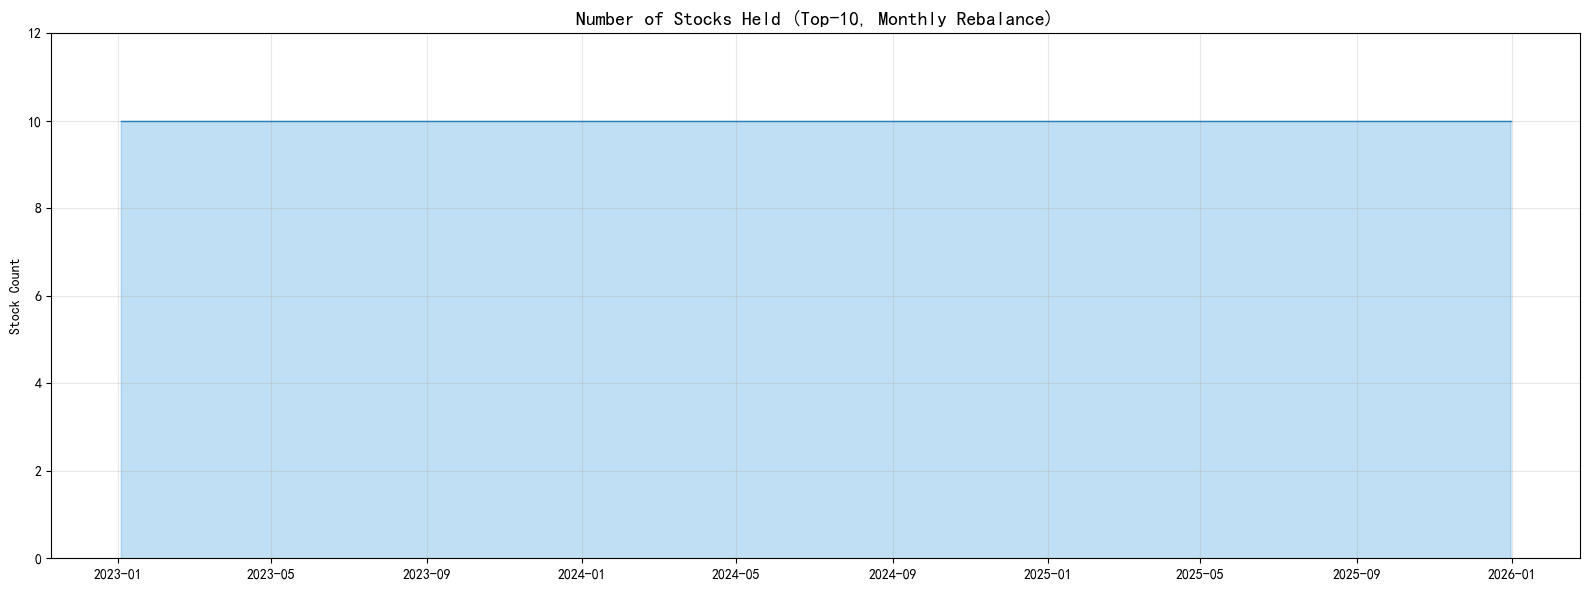

In [11]:
# 可视化调仓信号
fig, ax = plt.subplots(figsize=(16, 6))

hold_count = (portfolio_weights > 0).sum(axis=1)
ax.fill_between(hold_count.index, hold_count.values, alpha=0.3, color='#3498db')
ax.plot(hold_count.index, hold_count.values, color='#2980b9', linewidth=1)
ax.set_title(f'Number of Stocks Held (Top-{TOP_K}, Monthly Rebalance)', fontsize=14, fontweight='bold')
ax.set_ylabel('Stock Count')
ax.set_ylim(0, TOP_K + 2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results/04_holdings.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 保存模型输出

In [12]:
# 保存持仓矩阵和复合因子
portfolio_weights.to_csv('data/portfolio_weights.csv')
composite_factor.to_frame('composite').to_csv('data/composite_factor.csv')

print('=' * 50)
print('模型输出已保存:')
print(f'  持仓权重: data/portfolio_weights.csv')
print(f'  复合因子: data/composite_factor.csv')
print('=' * 50)

模型输出已保存:
  持仓权重: data/portfolio_weights.csv
  复合因子: data/composite_factor.csv


## 小结

✅ 完成因子标准化（去极值、Z-score）
✅ 对比了等权/IC加权/IC_IR加权三种合成方式
✅ 构建了IC_IR加权的复合因子
✅ 生成了月度调仓的Top-K选股持仓矩阵

下一步: [05_backtest.ipynb](./05_backtest.ipynb) 回测与绩效分析